In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid
import mpl_scatter_density
from matplotlib.colors import LinearSegmentedColormap
import pyBigWig

**Finding top peak signal for cycle 1 removed calls**

In [2]:
#load npz file
added_delta_all_cycles = []
removed_delta_all_cycles = []
added_flat_inds_all_cycles = []
removed_flat_inds_all_cycles = []

for i in range(1, 11):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffbiosample_sorteddiffdhs_fillsize100unique_cycle'+str(i)+'_added_removed_CT20220302.npz'
    cycle_np_file = np.load(filename)
    added_delta_all_cycles.append(cycle_np_file['added_delta'])
    removed_delta_all_cycles.append(cycle_np_file['removed_delta'])
    added_flat_inds_all_cycles.append(cycle_np_file['added_flat_inds'])
    removed_flat_inds_all_cycles.append(cycle_np_file['removed_flat_inds'])

In [3]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [4]:
file = '/home/ctrader/NMF_data/DHS_signal_matrix/DHS_peak_signal_hg38.75_20.normalized.GRCh38_no_alts_array_CT20220215.npy'
DHS_peak_signal_array = np.load(file)

In [5]:
n_biosamples, n_DHSs = DHS_peak_signal_array.shape

In [6]:
#loading biosample metadata
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
biosample_df = pd.read_csv(tsv_file, delimiter="\t")

In [7]:
#finding peak signal values of added calls
removed_peak_signal_all_cycles = []
for i in range(10):
    print(i)
    removed_peak_signal_single_cycle = []
    for biosample, dhs in zip((removed_flat_inds_all_cycles[i] // n_DHSs), (removed_flat_inds_all_cycles[i] % n_DHSs)):
        removed_peak_signal_single_cycle.append(DHS_peak_signal_array[biosample, dhs])
    removed_peak_signal_single_cycle = np.array(removed_peak_signal_single_cycle)
    removed_peak_signal_all_cycles.append(removed_peak_signal_single_cycle)

0
1
2
3
4
5
6
7
8
9


In [8]:
#looking into the top peak signal -1 removed calls
top_100_peak_scores = np.flip(np.sort(removed_peak_signal_all_cycles[0])[-100:])

top_100_neg1_peak_signal_flat_inds = removed_flat_inds_all_cycles[0][np.argsort(-removed_peak_signal_all_cycles[0])[:100]]
top_100_neg1_peak_signal_DHS_inds = top_100_neg1_peak_signal_flat_inds % n_DHSs
top_100_neg1_peak_signal_biosample_inds = top_100_neg1_peak_signal_flat_inds // n_DHSs
top_100_neg1_peak_signal_biosamples = np.array(biosample_df.loc[top_100_neg1_peak_signal_biosample_inds]['Biosample name'])

top_100_neg1_peak_signal_chr = np.array(DHS_metadata.loc[top_100_neg1_peak_signal_DHS_inds]['seqname'])
top_100_neg1_peak_signal_start = np.array(DHS_metadata.loc[top_100_neg1_peak_signal_DHS_inds]['start'])
top_100_neg1_peak_signal_end = np.array(DHS_metadata.loc[top_100_neg1_peak_signal_DHS_inds]['end'])

In [16]:
today = date.today()
bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_delta_100unique_top_100_peak_signal_removed_calls_cycle1_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(100):
    f.write(str(top_100_neg1_peak_signal_chr[i]) + '\t' + str(top_100_neg1_peak_signal_start[i]) + '\t' + str(top_100_neg1_peak_signal_end[i]) + '\t' + str(top_100_peak_scores[i]) + ' ' + str(top_100_neg1_peak_signal_biosamples[i]) + '\n')
f.close()
link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_delta_100unique_top_100_peak_signal_removed_calls_cycle1_CT' + today.strftime("%Y%m%d") + '.bed'
print(link_path)

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_delta_100unique_top_100_peak_signal_removed_calls_cycle1_CT20220304.bed


**Seeing if there examples of good removals in top peak signal removed calls**

In [9]:
comps = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

official_order = np.array([6, 4, 14, 8, 11, 13, 2, 7, 12, 1, 3, 5, 15, 10, 9, 0])
color = np.array(color)[official_order]
comps = np.array(comps)[official_order]

In [10]:
cycle0_dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')

In [11]:
filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffbiosample_sorteddiffdhs_fillsize100unique_cycle1_CT20220301.npz'
cycle_np_file = np.load(filename)
diff_flat = cycle_np_file['diff_flat_array']

1) BigWig Signal at DHS 3.25471 for Removed Call in Biosample Skin_Keratinocytes with Peak Signal=104.294
Delta Flip, Flip Size=100 Unique Delta Values


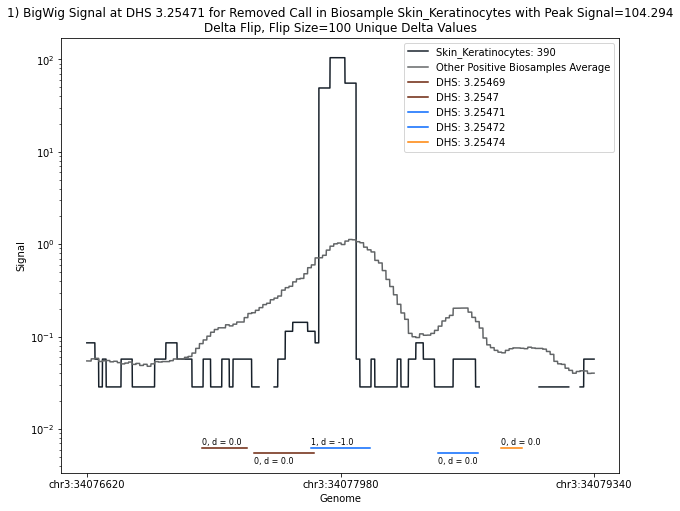

2) BigWig Signal at DHS 5.8642621 for Removed Call in Biosample Skin_Keratinocytes with Peak Signal=76.7927
Delta Flip, Flip Size=100 Unique Delta Values


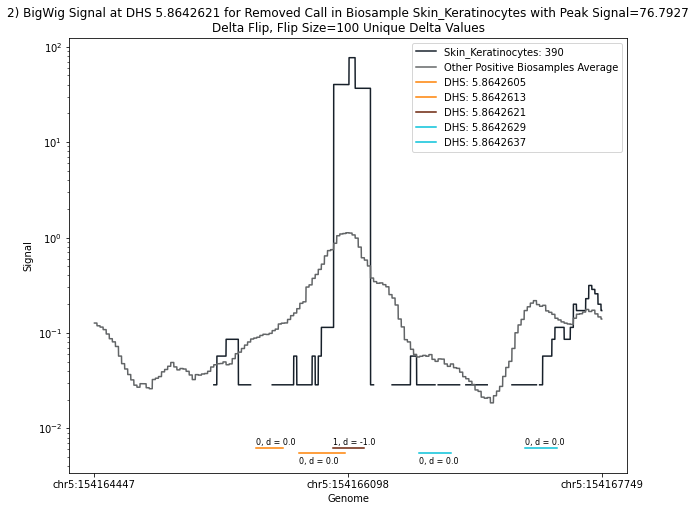

3) BigWig Signal at DHS 6.2045652 for Removed Call in Biosample Skin_Keratinocytes with Peak Signal=29.3577
Delta Flip, Flip Size=100 Unique Delta Values


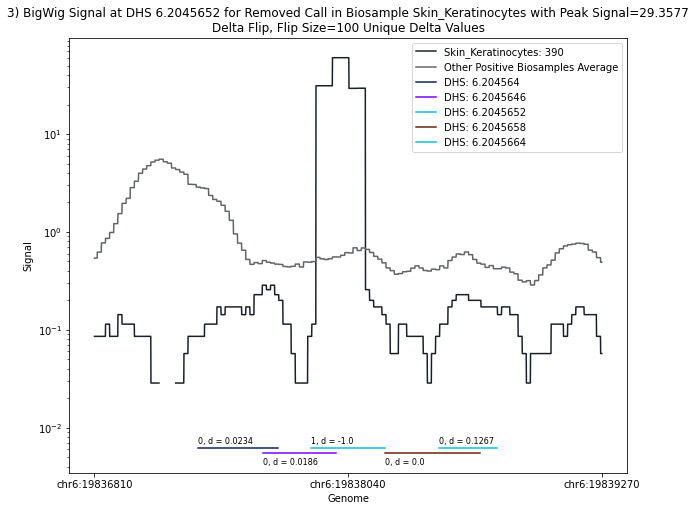

4) BigWig Signal at DHS 2.962169 for Removed Call in Biosample Skin_Keratinocytes with Peak Signal=12.0515
Delta Flip, Flip Size=100 Unique Delta Values


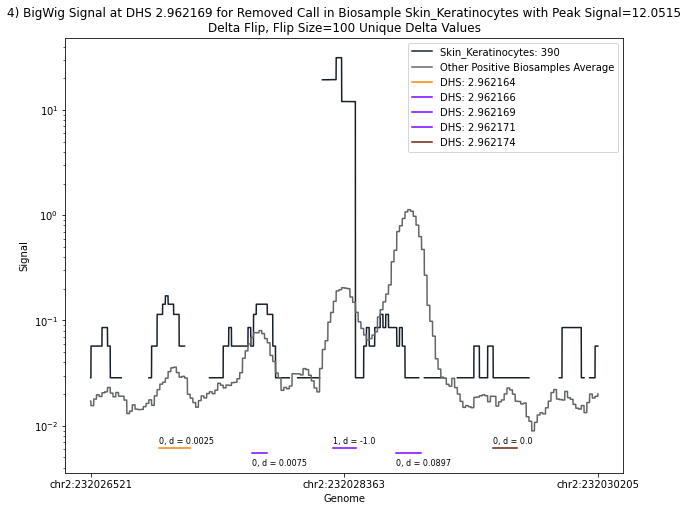

5) BigWig Signal at DHS 11.656873 for Removed Call in Biosample Hela with Peak Signal=11.7659
Delta Flip, Flip Size=100 Unique Delta Values


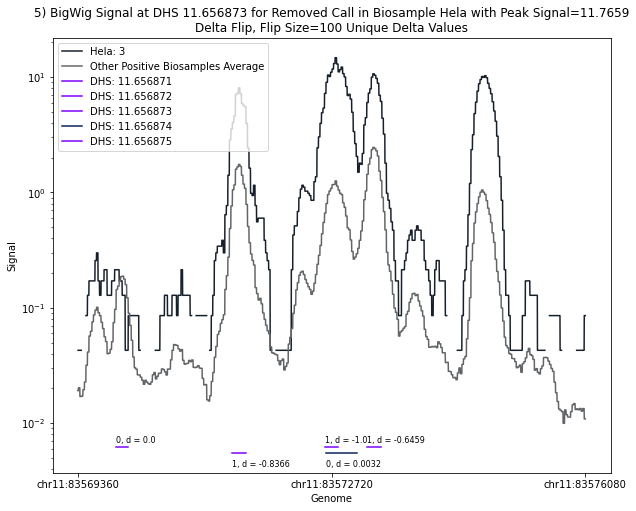

6) BigWig Signal at DHS 22.505828 for Removed Call in Biosample GM06990 with Peak Signal=11.375
Delta Flip, Flip Size=100 Unique Delta Values


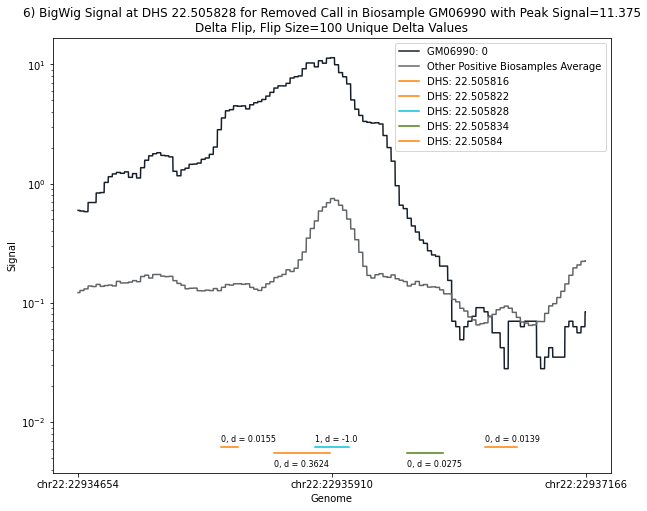

7) BigWig Signal at DHS 19.748262 for Removed Call in Biosample Skin_Keratinocytes with Peak Signal=10.6954
Delta Flip, Flip Size=100 Unique Delta Values


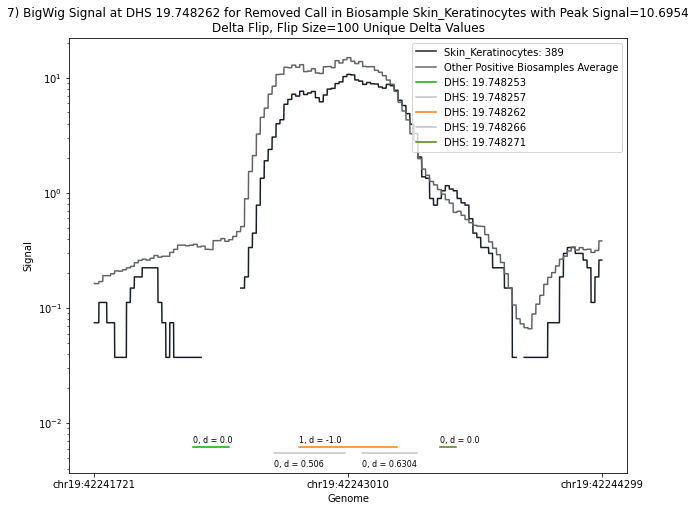

8) BigWig Signal at DHS 19.716286 for Removed Call in Biosample PANC1 with Peak Signal=9.58925
Delta Flip, Flip Size=100 Unique Delta Values


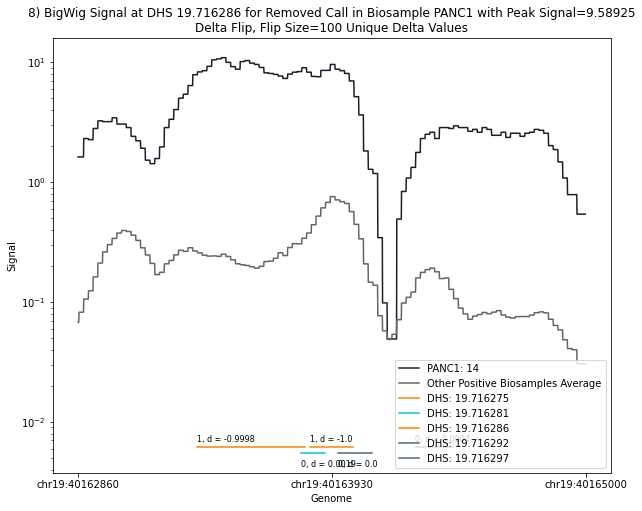

9) BigWig Signal at DHS 8.399226 for Removed Call in Biosample LNCap with Peak Signal=9.44852
Delta Flip, Flip Size=100 Unique Delta Values


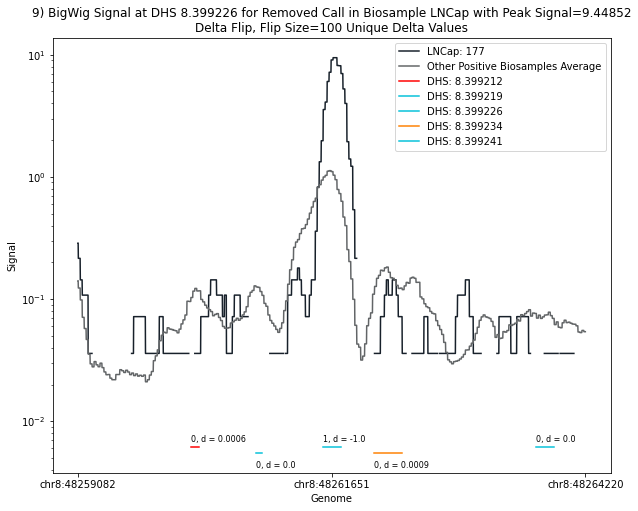

10) BigWig Signal at DHS 3.198976 for Removed Call in Biosample LNCap with Peak Signal=9.05334
Delta Flip, Flip Size=100 Unique Delta Values


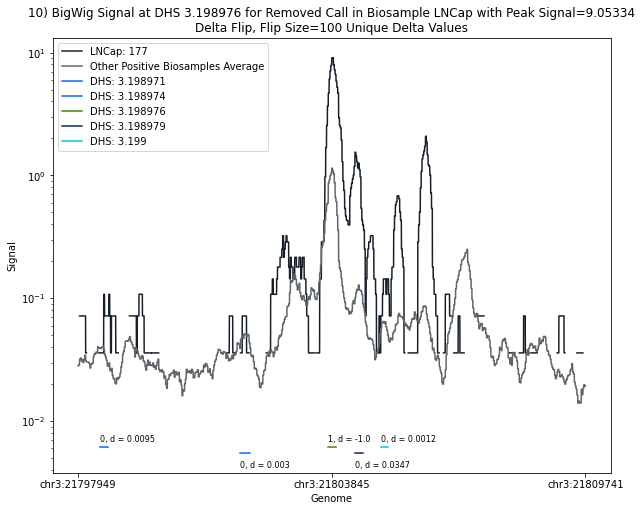

11) BigWig Signal at DHS 13.90778 for Removed Call in Biosample WERI_Rb1 with Peak Signal=8.97441
Delta Flip, Flip Size=100 Unique Delta Values


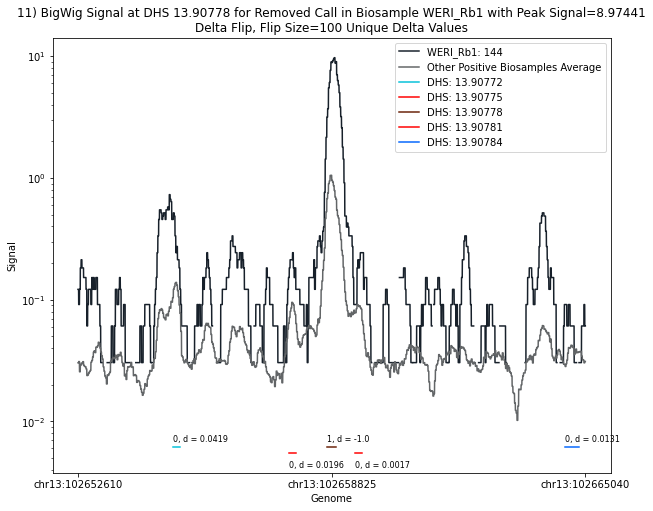

12) BigWig Signal at DHS 15.692292 for Removed Call in Biosample HRE with Peak Signal=8.59358
Delta Flip, Flip Size=100 Unique Delta Values


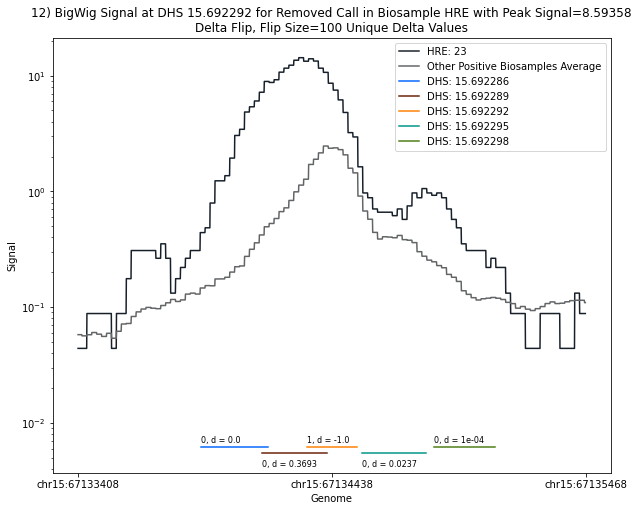

13) BigWig Signal at DHS 2.866872 for Removed Call in Biosample LHCN_M2 with Peak Signal=8.28356
Delta Flip, Flip Size=100 Unique Delta Values


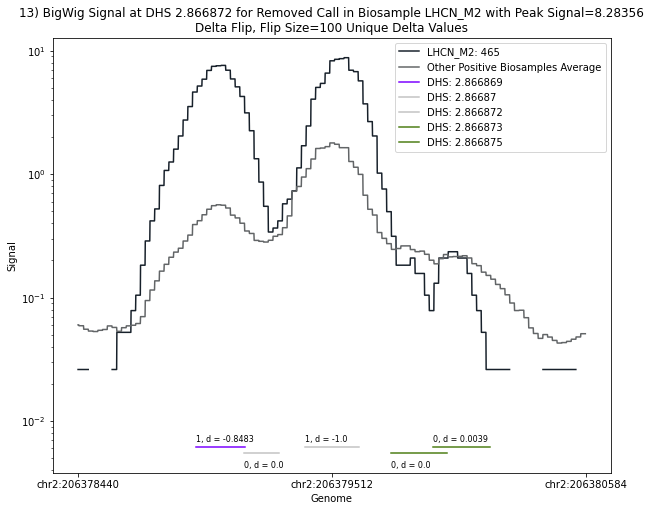

14) BigWig Signal at DHS 5.480737 for Removed Call in Biosample HIPEpiC with Peak Signal=8.21395
Delta Flip, Flip Size=100 Unique Delta Values


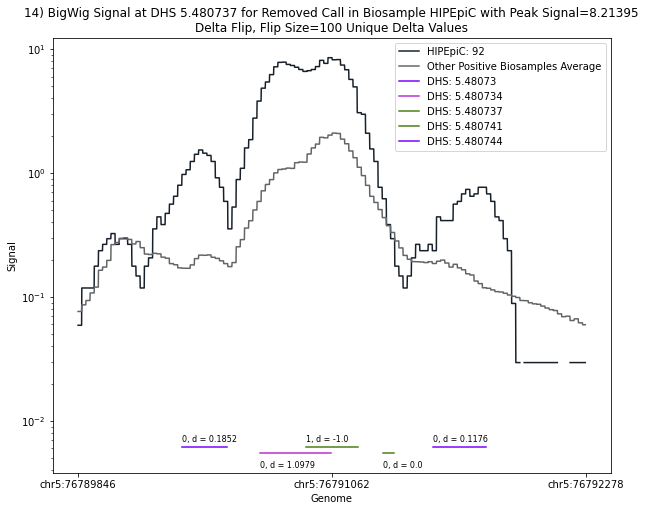

15) BigWig Signal at DHS 15.692292 for Removed Call in Biosample HRE with Peak Signal=8.20305
Delta Flip, Flip Size=100 Unique Delta Values


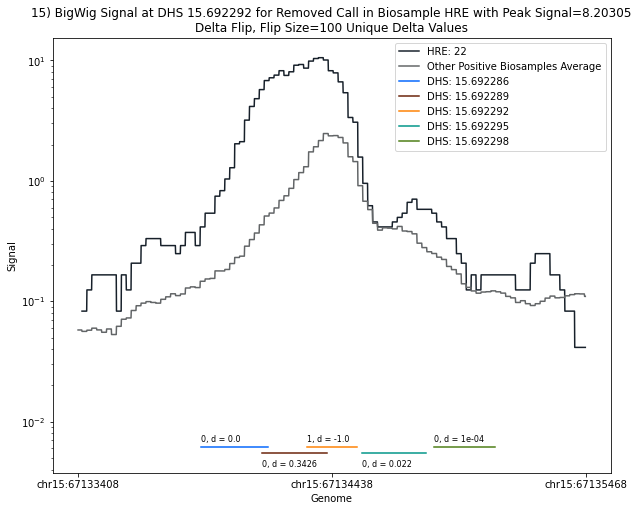

16) BigWig Signal at DHS 8.285177 for Removed Call in Biosample Hela with Peak Signal=8.08636
Delta Flip, Flip Size=100 Unique Delta Values


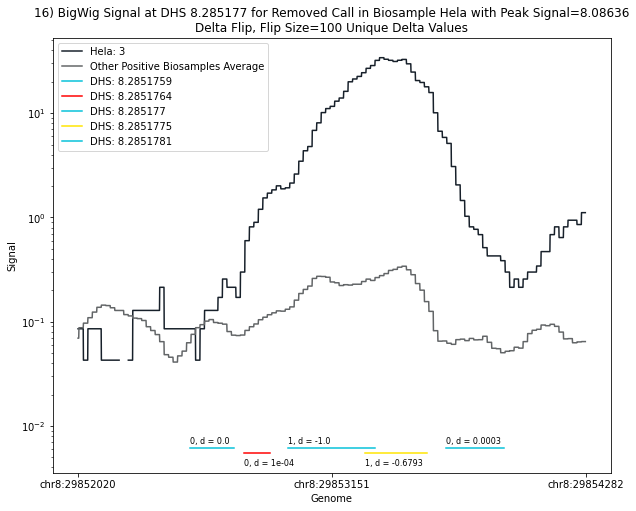

17) BigWig Signal at DHS 1.311706 for Removed Call in Biosample HMEC with Peak Signal=7.97271
Delta Flip, Flip Size=100 Unique Delta Values


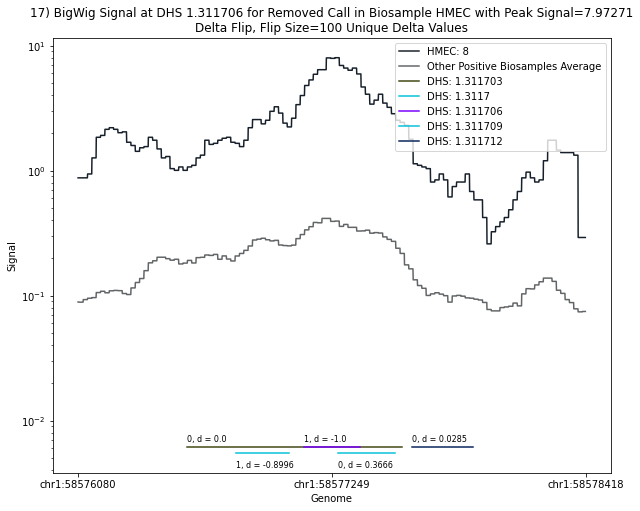

18) BigWig Signal at DHS 1.6490676 for Removed Call in Biosample LNCap with Peak Signal=7.90371
Delta Flip, Flip Size=100 Unique Delta Values


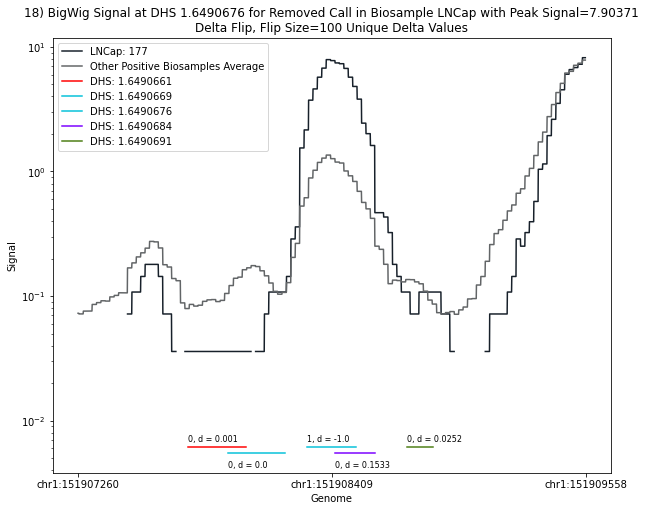

19) BigWig Signal at DHS 15.494661 for Removed Call in Biosample fStomach with Peak Signal=7.88248
Delta Flip, Flip Size=100 Unique Delta Values


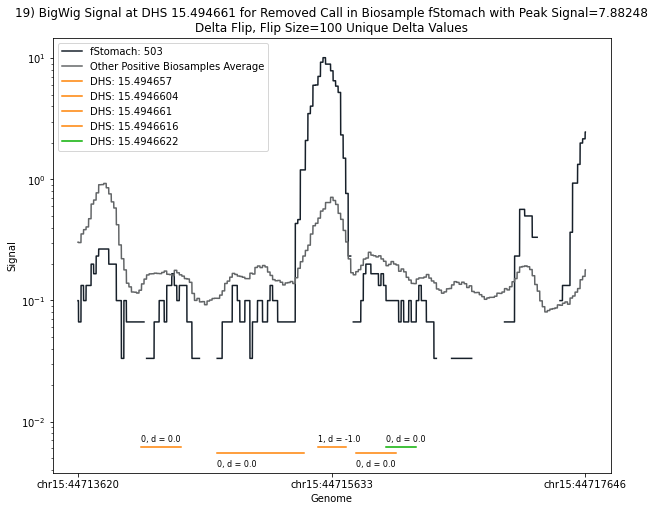

20) BigWig Signal at DHS 2.170737 for Removed Call in Biosample HT29 with Peak Signal=7.82996
Delta Flip, Flip Size=100 Unique Delta Values


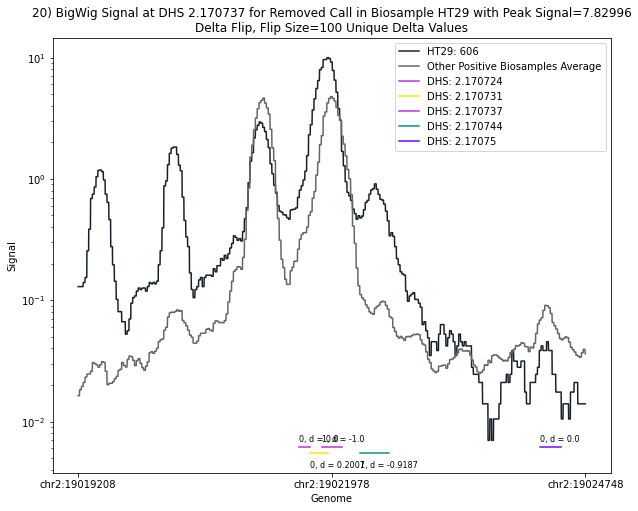

In [17]:
for i in range(20):
    plotting_signal(i)

In [16]:
def plotting_signal(i, buffer=500):
    #find biosample with call of interest
    biosample = top_100_neg1_peak_signal_biosample_inds[i]
    #dhs of call of interest
    dhs = top_100_neg1_peak_signal_DHS_inds[i]
    #chrm for DHS
    chrm = top_100_neg1_peak_signal_chr[i]
    #two upstream and two downstream DHSs
    dhss_inds_to_plot = np.arange((dhs-2),(dhs+3))
    #presence or absence in original matrix
    dhss_to_plot_original_vals = cycle0_dhs_arr[biosample, dhss_inds_to_plot].astype(int)
    #delta values of calls
    dhss_to_plot_delta_vals = diff_flat[dhss_inds_to_plot + (biosample * n_DHSs)]
    #metadata for each DHS
    dhss_to_plot_df = DHS_metadata.loc[dhss_inds_to_plot]
    dhss_to_plot_comps = np.array(dhss_to_plot_df['component'])
    dhss_to_plot_comp_color = []
    for comp in dhss_to_plot_comps:
        comp_ind = np.where(comps==comp)[0]
        dhss_to_plot_comp_color.append(color[comp_ind][0])
    dhss_to_plot_names = np.array(DHS_metadata.loc[dhss_inds_to_plot]['identifier'])
    dhss_to_plot_start = np.array(DHS_metadata.loc[dhss_inds_to_plot]['start'])
    dhss_to_plot_end = np.array(DHS_metadata.loc[dhss_inds_to_plot]['end'])
    #placing DHS of interest in center
    first_dhs_start = dhss_to_plot_start[0]
    last_dhs_end = dhss_to_plot_start[-1]
    dhs_of_interest_center = int((dhss_to_plot_start[2] + dhss_to_plot_end[2])/2)
    max_dhs_dist_to_center = np.max([dhs_of_interest_center - first_dhs_start, last_dhs_end - dhs_of_interest_center])
    start = dhs_of_interest_center - buffer - max_dhs_dist_to_center
    end = dhs_of_interest_center + buffer + max_dhs_dist_to_center

    #load bw file for biosample of interest
    agnum = biosample_df.loc[biosample]['Altius Aggregation ID'][2:]
    lnnum = biosample_df.loc[biosample]['Altius Library ID']
    if lnnum[-1].isalpha():
        lnnum = lnnum[:-1]
    read_in_question_biosample_name = biosample_df.loc[biosample]['Biosample name']
    # print(agnum)
    # print(lnnum)
    filename = '/net/seq/data/aggregations/' + lnnum + '/aggregation-' + agnum + '/' + lnnum + '.75_20.normalized.GRCh38_no_alts.bw'
    bw_file = pyBigWig.open(filename)
    read_in_question = bw_file.values(chrm, 
                                      start, 
                                      end, 
                                      numpy=True)
    
    #finding all biosamples positive for call of interest and removing biosample of interest 
    other_positive_biosamples = np.where(cycle0_dhs_arr[:, dhs]==True)[0]
    other_positive_biosamples = other_positive_biosamples[other_positive_biosamples!=biosample]
    
    #load bw file for all positive biosamples
    base_signal_values = []
    for base_biosample in other_positive_biosamples: 
        agnum = biosample_df.loc[base_biosample]['Altius Aggregation ID'][2:]
        lnnum = biosample_df.loc[base_biosample]['Altius Library ID']
        if lnnum[-1].isalpha():
            lnnum = lnnum[:-1]
        base_read_biosample_name = biosample_df.loc[base_biosample]['Biosample name']
    #     print(agnum, lnnum)
        filename = '/net/seq/data/aggregations/' + lnnum + '/aggregation-' + agnum + '/' + lnnum + '.75_20.normalized.GRCh38_no_alts.bw'
        bw_file = pyBigWig.open(filename)
        base_read = bw_file.values(chrm, 
                                   start, 
                                   end, 
                                   numpy=True)
        base_signal_values.append(base_read)
    base_signal_values = np.array(base_signal_values)
    #bp average signal
    base_signal_values_ave = np.nanmean(base_signal_values, axis=0)
    
    #plotting
    fig = plt.figure(figsize=(10,8))
    fig.patch.set_facecolor('white')

    plt.plot(np.arange(start, end), read_in_question, color='#17202A')
    plt.plot(np.arange(start, end), base_signal_values_ave, color='#626567')
    for ind in range(5):
        if ind % 2 == 0:
            line_height = 0.0062
        else:
            line_height = 0.0055
        plt.plot(np.arange(dhss_to_plot_start[ind], dhss_to_plot_end[ind]), np.zeros(dhss_to_plot_end[ind] - dhss_to_plot_start[ind])+line_height, color=dhss_to_plot_comp_color[ind])
        if ind % 2 == 0:
            txt_height = 0.0068
        else:
            txt_height = 0.0042
        plt.text(dhss_to_plot_start[ind], txt_height, str(dhss_to_plot_original_vals[ind]) + ', d = ' + str(np.round(dhss_to_plot_delta_vals[ind], 4)), fontsize=8)

    plt.xticks([start, int((end+start)/2), end],
                 [chrm + ':' + str(start), chrm + ':' + str(int((end+start)/2)), chrm + ':' + str(end)])

    plt.legend([read_in_question_biosample_name + ': ' + str(biosample), 
                'Other Positive Biosamples Average',
                'DHS: ' + dhss_to_plot_names[0],
                'DHS: ' + dhss_to_plot_names[1],
                'DHS: ' + dhss_to_plot_names[2],
                'DHS: ' + dhss_to_plot_names[3],
                'DHS: ' + dhss_to_plot_names[4],])
    plt.yscale('log')
    plt.xlabel('Genome')
    plt.ylabel('Signal')
    plot_title = '%s) BigWig Signal at DHS %s for Removed Call in Biosample %s with Peak Signal=%s\nDelta Flip, Flip Size=100 Unique Delta Values' %((i+1), dhss_to_plot_names[2], read_in_question_biosample_name, top_100_peak_scores[i])
    print(plot_title)
    plt.title(plot_title)
    plt.show()